# Issue #299 — BEST_FULL-anchored residual learning

This notebook reproduces `exact BEST_FULL + learned residual` on the 227-issue
matched calendar. The model trains on 2019–2021, uses 2022 for the no-regression
gate, freezes for 2023, and cannot open 2024+ rows.

Primary conclusion: **RELATIVE_BASELINE_SIGNAL_NO_PROMOTION**. Dynamic residual
learning materially reduces the accepted baseline loss and drawdown, but 2023
remains negative and the learned action placement does not beat an
exposure-matched random permutation control.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "issue299").is_dir()
)
sys.path.insert(0, str(ROOT / "src"))
from issue299.experiment import run_experiment

OUTPUT = ROOT / "results/issue-299"
decision = run_experiment(ROOT, OUTPUT)
decision

{'issue': 299,
 'development_only': True,
 'train_years': [2019, 2020, 2021],
 'validation_year': 2022,
 'test_year': 2023,
 'sealed_years': '2024+ not read by model runner',
 'baseline_identity': 'accepted #167/#170 B0_BEST_FULL',
 'actions': {'BASELINE_ONLY': (),
  'BASELINE_SCALE_DOWN': ('CASH_OVERRIDE',),
  'BASELINE_PLUS_CORE': ('SMOOTH_M512',),
  'BASELINE_PLUS_TAIL': ('RARE_LOGIT_TOP64',),
  'BASELINE_PLUS_DIVERGENCE': ('DIVERGENCE_Z100_K1',),
  'BASELINE_PLUS_MIXED': ('SMOOTH_M512', 'RARE_LOGIT_TOP64')},
 'decision': {'verdict': 'RELATIVE_BASELINE_SIGNAL_NO_PROMOTION',
  'promotable': False,
  'relative_baseline_signal': True,
  'validation_gate_accepted': True,
  'guarded_source': 'LEARNED_RESIDUAL',
  'matched_support_issues': 227,
  'excluded_no_exact_baseline': 42,
  'static_train_action': 'BASELINE_PLUS_MIXED',
  'baseline_2023_capital_growth_pct': -20.751038032000004,
  'raw_learned_2023_capital_growth_pct': -9.10435953136689,
  'raw_learned_matched_lift_cny': 11646.67850

## Exact support and baseline reproduction

In [2]:
support = pd.read_csv(OUTPUT / "support_receipt.csv")
display(support.support_status.value_counts().rename("issues").to_frame())
display(json.loads((OUTPUT / "baseline_reproduction.json").read_text()))

,issues
support_status,
MATCHED_BASELINE_AND_FEATURES,227
EXCLUDED_NO_EXACT_BEST_FULL,42


{'matched_issues': 227,
 'active_issues': 122,
 'stake_identical': True,
 'pnl_identical': True,
 'gross_identical': True,
 'all_active_atomic_4374': True}

## Matched capital and residual lift

,evaluation_year,condition,terminal_capital_cny,capital_growth_pct,max_drawdown_pct,stake_cny,worst_rolling_10_pnl_cny,ex_largest_pnl_cny
3,2022,BEST_FULL_BASELINE,85073.659381,-14.926341,26.604007,139968.0,-15902.592305,-27821.534022
4,2023,BEST_FULL_BASELINE,79248.961968,-20.751038,28.499383,153090.0,-24448.936166,-31647.371945
13,2022,STATIC_TRAIN_BASELINE_PLUS_MIXED,122334.254080,22.334254,35.248685,186688.0,-22156.867827,-24292.691998
14,2023,STATIC_TRAIN_BASELINE_PLUS_MIXED,102282.960496,2.282960,23.899574,194050.0,-20870.144266,-20413.429311
18,2022,LEARNED_RESIDUAL,104096.114878,4.096115,9.847750,49266.0,-6342.848252,-13950.386777
19,2023,LEARNED_RESIDUAL,90895.640469,-9.104360,13.551679,50418.0,-11852.362032,-14278.991692
23,2022,IDENTITY_SHUFFLED,106408.834235,6.408834,4.474320,56862.0,-4935.878146,-6486.359168
24,2023,IDENTITY_SHUFFLED,83653.368124,-16.346632,18.883611,52744.0,-15541.036557,-19037.389652
28,2022,RIDGE_RESIDUAL_CONTROL,100000.000000,0.000000,0.000000,0.0,0.000000,0.000000
29,2023,RIDGE_RESIDUAL_CONTROL,99355.755051,-0.644245,0.644245,4374.0,-644.244949,-644.244949


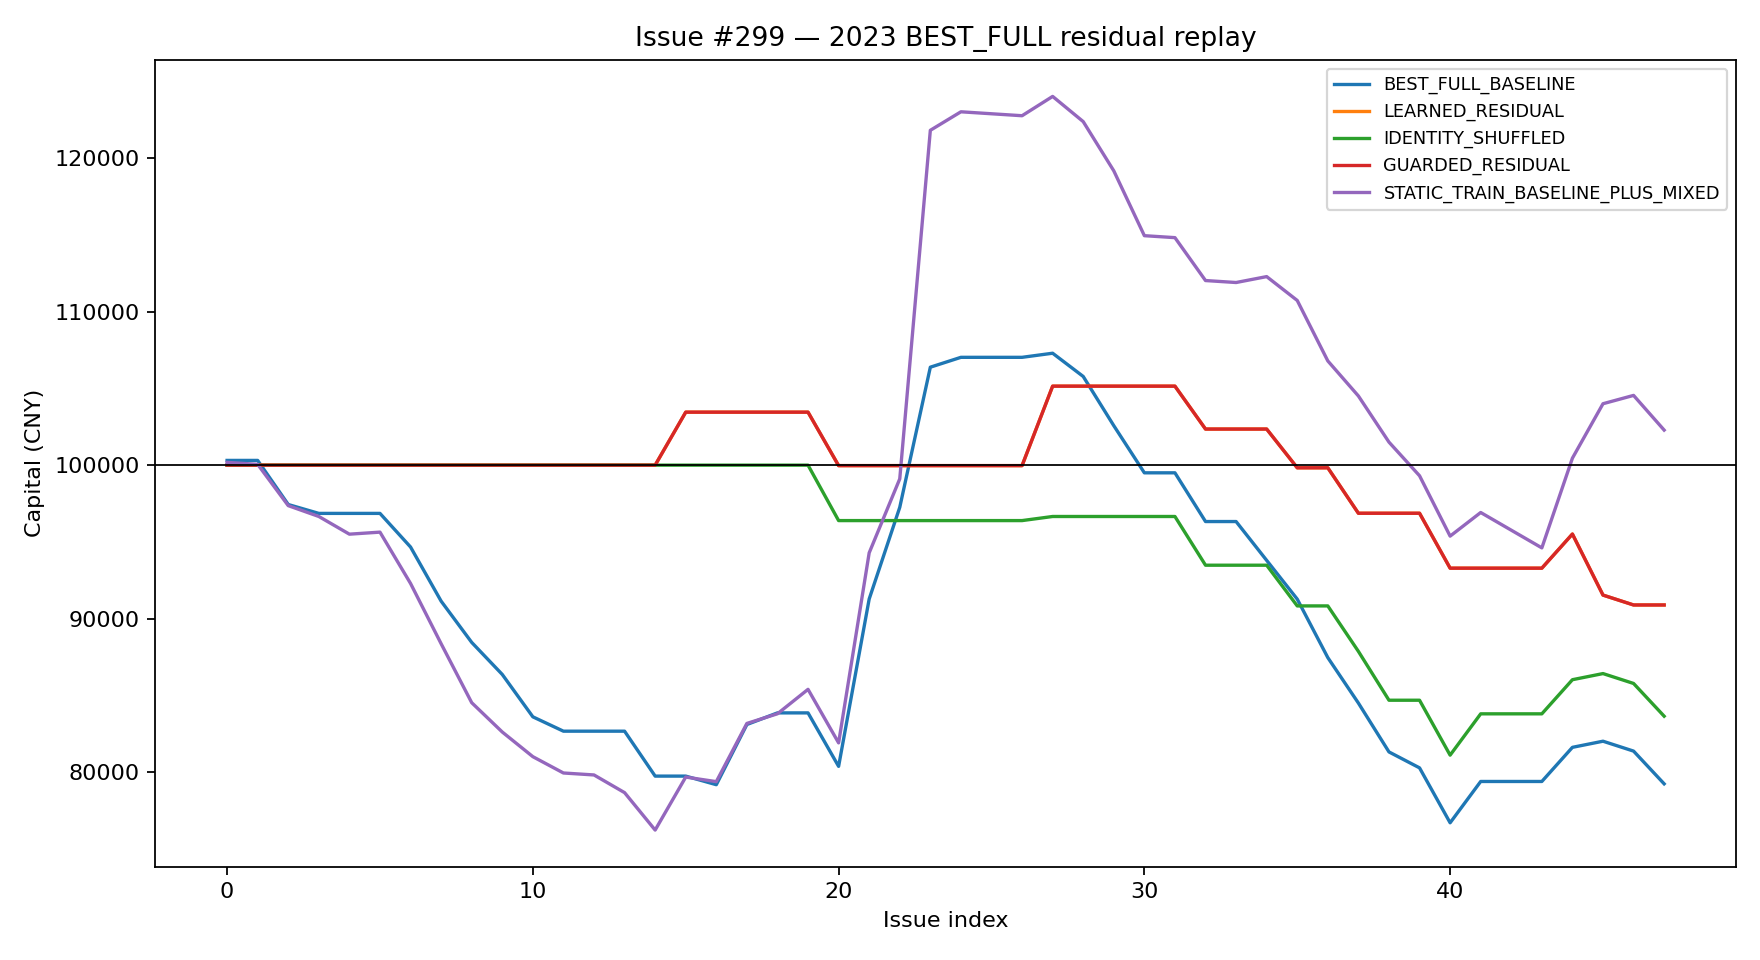

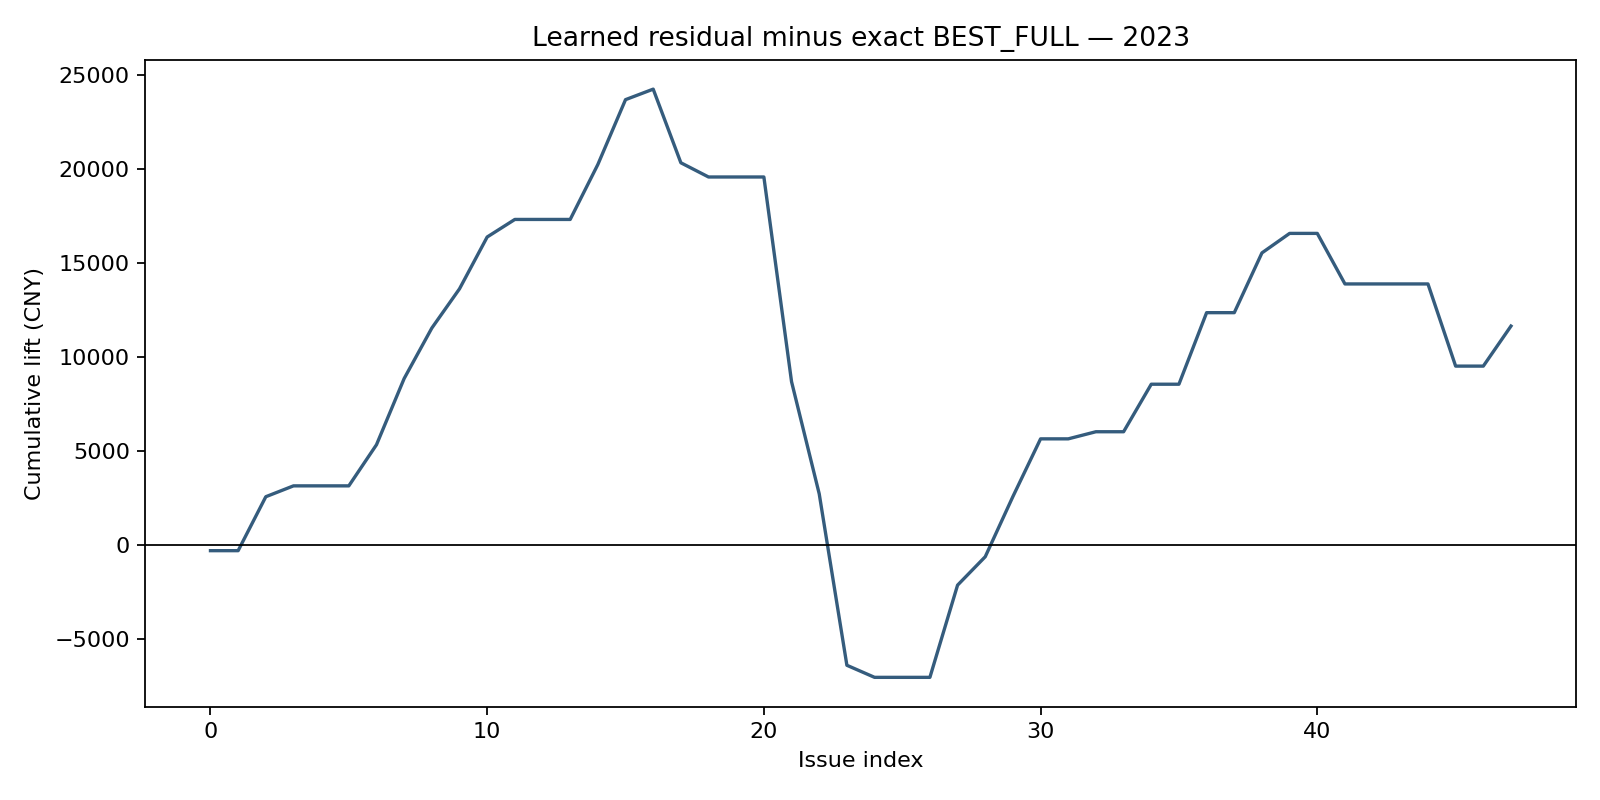

In [3]:
summary = pd.read_csv(OUTPUT / "policy_summary_by_year.csv")
focus = ["BEST_FULL_BASELINE", "LEARNED_RESIDUAL", "GUARDED_RESIDUAL",
         "RIDGE_RESIDUAL_CONTROL", "SELECTION_ONLY_GATE",
         "STATIC_TRAIN_BASELINE_PLUS_MIXED", "IDENTITY_SHUFFLED"]
cols = ["evaluation_year", "condition", "terminal_capital_cny",
        "capital_growth_pct", "max_drawdown_pct", "stake_cny",
        "worst_rolling_10_pnl_cny", "ex_largest_pnl_cny"]
display(summary[(summary.evaluation_year >= 2022) & summary.condition.isin(focus)][cols])
display(Image(filename=str(OUTPUT / "capital_paths_2023.png")))
display(Image(filename=str(OUTPUT / "learned_minus_best_full_2023.png")))

## What changed and whether placement added skill

,requested_action,issues,stake_cny,pnl_cny,incremental_pnl_cny,profitable_issue_rate
0,BASELINE_ONLY,3,4374.0,-644.244949,0.000000,0.00
1,BASELINE_PLUS_DIVERGENCE,8,39366.0,-9117.864670,533.754774,0.25
2,BASELINE_PLUS_MIXED,2,6678.0,657.750088,3830.165177,0.50
3,BASELINE_SCALE_DOWN,35,0.0,0.000000,7282.758550,0.00


,count,mean,std,min,5%,50%,95%,max
issue_year,,,,,,,,
2022,1000.0,100564.477959,16726.730828,71545.550718,81979.408344,95637.531498,139161.480439,177401.921099
2023,1000.0,96983.881666,14916.399976,61602.530562,75748.578192,95005.377594,124598.498689,153224.825715


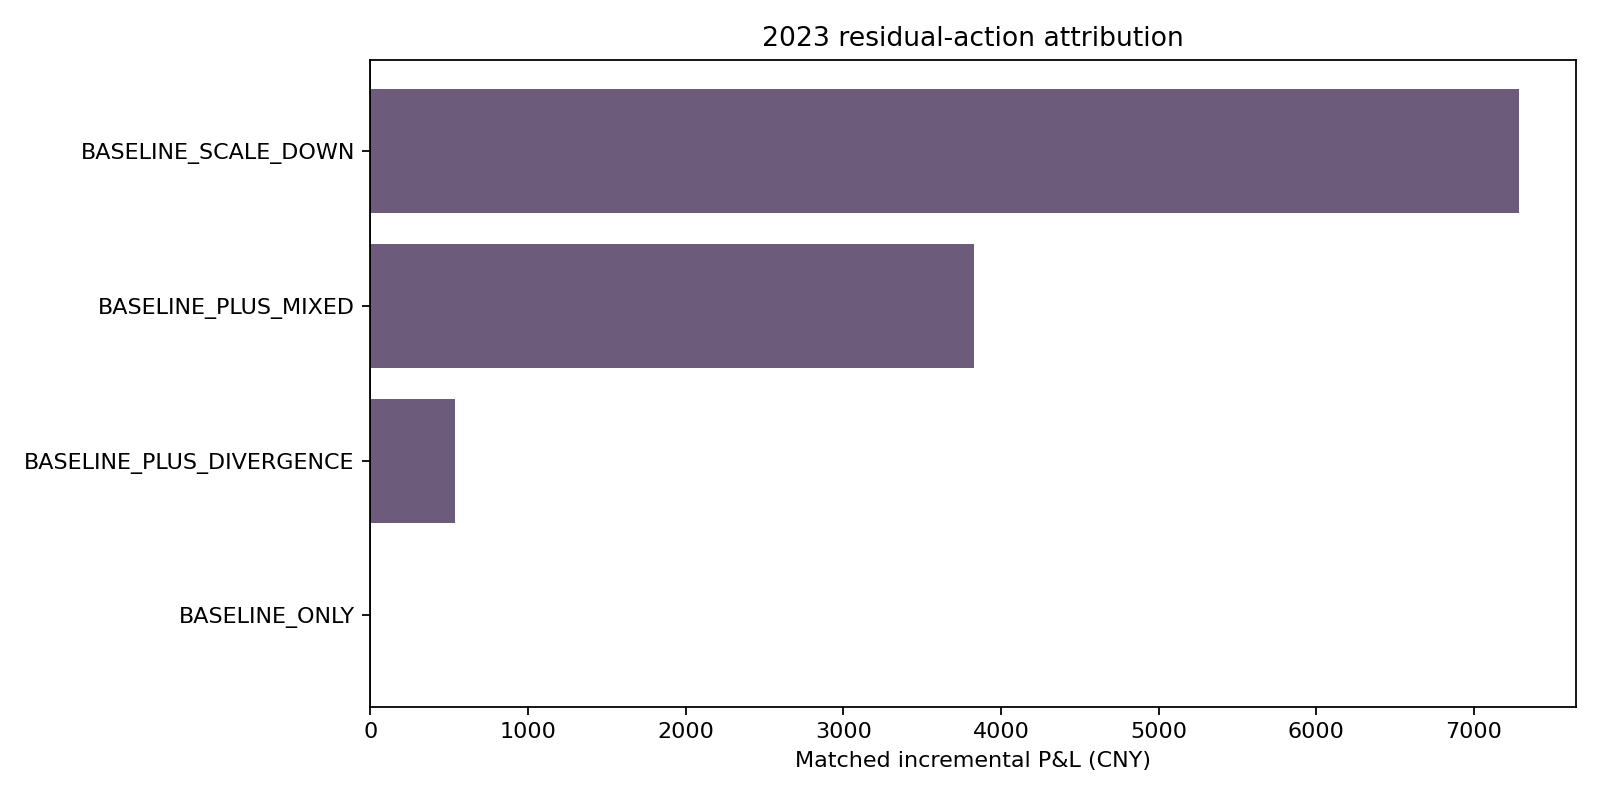

In [4]:
display(pd.read_csv(OUTPUT / "action_attribution_2023.csv"))
permutation = pd.read_csv(OUTPUT / "exposure_matched_permutation.csv")
display(permutation.groupby("issue_year").terminal_capital_cny.describe(percentiles=[.05,.5,.95]))
display(Image(filename=str(OUTPUT / "action_attribution_2023.png")))

## Calibration, seed stability and validation gate

,seed,issue_year,condition,issues,funded_issues,initial_capital_cny,terminal_capital_cny,capital_growth_pct,stake_cny,pnl_cny,...,rolling_20_loss_probability,positive_years,largest_issue_pnl_share,ex_largest_pnl_cny,positive_contribution_hhi,positive_contribution_ess,maximum_completed_recovery_issues,terminal_underwater_issues,minimum_capital_cny,ruin_boundary_hit
0,299001,2022,LEARNED_SEED_299001,53,10,100000.0,103069.832305,3.069832,49266.0,3069.832305,...,0.794118,1,5.878660,-14976.669350,1.000000,1.000000,2,46,97420.517084,False
1,299001,2023,LEARNED_SEED_299001,48,9,100000.0,87444.337292,-12.555663,49266.0,-12555.662708,...,0.793103,0,NaN,-17730.294869,0.579643,1.725199,7,16,87444.337292,False
2,299002,2022,LEARNED_SEED_299002,53,9,100000.0,103240.684173,3.240684,44892.0,3240.684173,...,0.764706,1,5.568732,-14805.817482,1.000000,1.000000,2,46,97420.517084,False
3,299002,2023,LEARNED_SEED_299002,48,12,100000.0,81732.996987,-18.267003,56072.0,-18267.003013,...,0.793103,0,NaN,-21718.306190,0.409663,2.441029,0,28,81732.996987,False
4,299003,2022,LEARNED_SEED_299003,53,8,100000.0,100141.029931,0.141030,49266.0,141.029931,...,0.764706,1,127.962210,-17905.471724,1.000000,1.000000,2,46,97420.517084,False
5,299003,2023,LEARNED_SEED_299003,48,10,100000.0,90895.640469,-9.104360,50418.0,-9104.359531,...,0.689655,0,NaN,-14278.991692,0.370708,2.697539,7,16,90895.640469,False
6,299004,2022,LEARNED_SEED_299004,53,7,100000.0,107802.080637,7.802081,36144.0,7802.080637,...,0.764706,1,2.313037,-10244.421018,1.000000,1.000000,2,46,97420.517084,False
7,299004,2023,LEARNED_SEED_299004,48,10,100000.0,90895.640469,-9.104360,50418.0,-9104.359531,...,0.689655,0,NaN,-14278.991692,0.370708,2.697539,7,16,90895.640469,False
8,299005,2022,LEARNED_SEED_299005,53,10,100000.0,102977.654842,2.977655,53640.0,2977.654842,...,0.794118,1,6.060643,-15068.846813,1.000000,1.000000,2,46,97420.517084,False
9,299005,2023,LEARNED_SEED_299005,48,12,100000.0,86683.052408,-13.316948,55944.0,-13316.947592,...,0.793103,0,NaN,-16768.250769,0.290621,3.440906,0,28,85202.554380,False


{'accepted': True,
 'decision': 'LEARNED_RESIDUAL',
 'checks': {'terminal_capital_not_worse': True,
  'max_drawdown_not_worse': True,
  'worst_rolling_10_not_worse': True,
  'ex_largest_matched_lift_nonnegative': True,
  'at_least_three_of_five_seeds_positive_lift': True},
 'learned_validation': {'condition': 'LEARNED_RESIDUAL',
  'issues': 53,
  'funded_issues': 9,
  'initial_capital_cny': 100000.0,
  'terminal_capital_cny': 104096.11487796486,
  'capital_growth_pct': 4.096114877964863,
  'stake_cny': 49266.0,
  'pnl_cny': 4096.11487796486,
  'turnover_roi_pct': 8.314283436781675,
  'mean_deployed_capital_fraction': 0.00860190304250347,
  'mean_effective_cash_fraction': 0.9913980969574965,
  'max_drawdown_pct': 9.847750453058879,
  'max_drawdown_cny': 11370.903860999999,
  'longest_losing_issue_streak': 2,
  'longest_active_losing_issue_streak': 7,
  'longest_calendar_no_payout_issue_streak': 20,
  'longest_active_no_payout_issue_streak': 0,
  'calendar_payout_issue_rate': 0.169811320

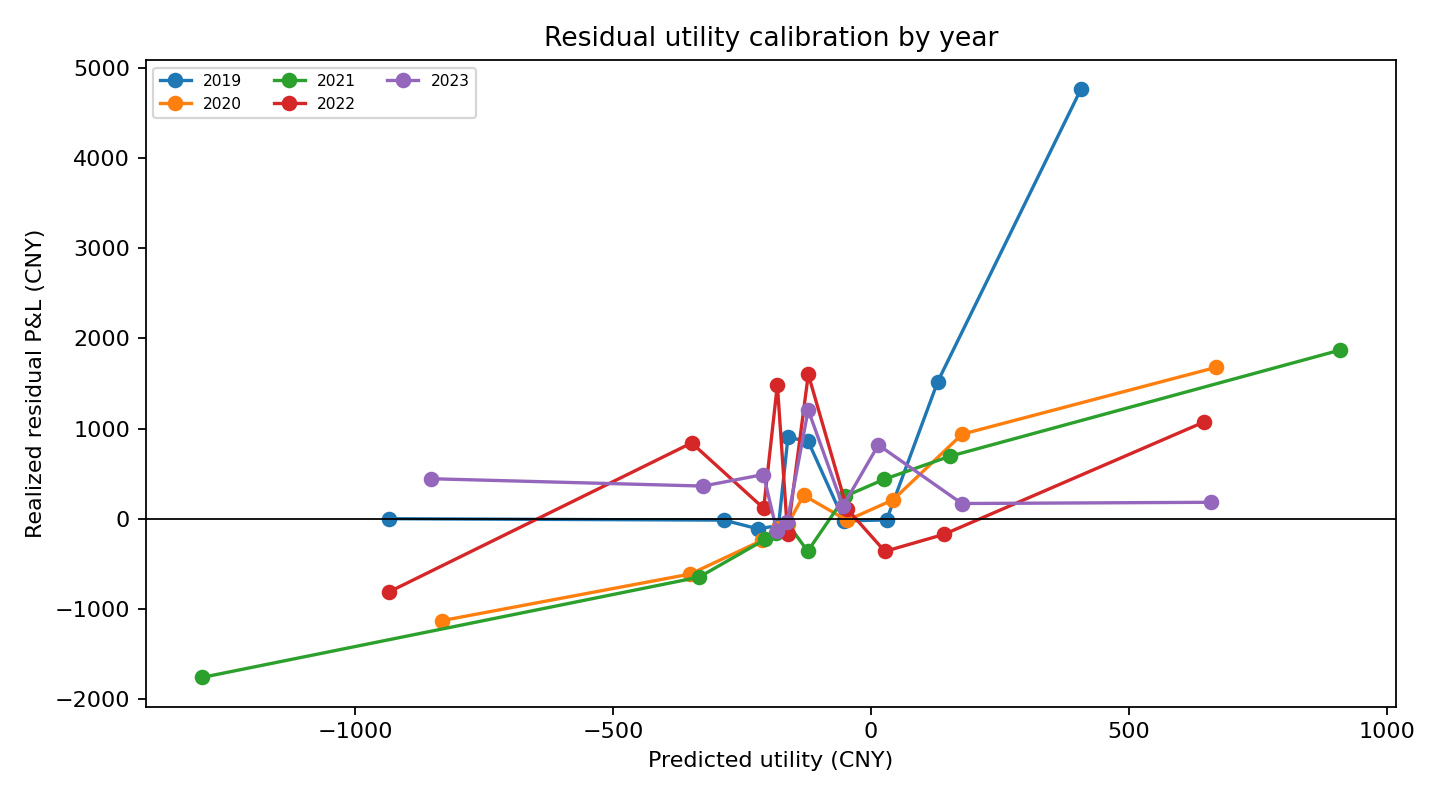

In [5]:
display(pd.read_csv(OUTPUT / "seed_summary.csv"))
display(json.loads((OUTPUT / "validation_gate.json").read_text()))
display(Image(filename=str(OUTPUT / "residual_calibration.png")))

## Machine decision and manifest

In [6]:
display(json.loads((OUTPUT / "decision.json").read_text()))
display(json.loads((OUTPUT / "manifest.json").read_text()))

{'issue': 299,
 'development_only': True,
 'train_years': [2019, 2020, 2021],
 'validation_year': 2022,
 'test_year': 2023,
 'sealed_years': '2024+ not read by model runner',
 'baseline_identity': 'accepted #167/#170 B0_BEST_FULL',
 'actions': {'BASELINE_ONLY': [],
  'BASELINE_SCALE_DOWN': ['CASH_OVERRIDE'],
  'BASELINE_PLUS_CORE': ['SMOOTH_M512'],
  'BASELINE_PLUS_TAIL': ['RARE_LOGIT_TOP64'],
  'BASELINE_PLUS_DIVERGENCE': ['DIVERGENCE_Z100_K1'],
  'BASELINE_PLUS_MIXED': ['SMOOTH_M512', 'RARE_LOGIT_TOP64']},
 'decision': {'verdict': 'RELATIVE_BASELINE_SIGNAL_NO_PROMOTION',
  'promotable': False,
  'relative_baseline_signal': True,
  'validation_gate_accepted': True,
  'guarded_source': 'LEARNED_RESIDUAL',
  'matched_support_issues': 227,
  'excluded_no_exact_baseline': 42,
  'static_train_action': 'BASELINE_PLUS_MIXED',
  'baseline_2023_capital_growth_pct': -20.751038032000004,
  'raw_learned_2023_capital_growth_pct': -9.10435953136689,
  'raw_learned_matched_lift_cny': 11646.678500633

{'issue': 299,
 'files': [{'path': 'results/issue-299/action_attribution_2023.csv',
   'bytes': 321,
   'sha256': 'de486ab7335d00006275a872a6ccf9c60f2e66305155c7619de55f8cb4dc8d47'},
  {'path': 'results/issue-299/action_attribution_2023.png',
   'bytes': 44789,
   'sha256': '2b69a4556614b47c847a6c258c79b11bcbeed8d7466d7c18384d7c71a77edda2'},
  {'path': 'results/issue-299/baseline_reproduction.json',
   'bytes': 165,
   'sha256': '178da677f98a0a63a645c906da0c788684736e087f57d43984b31198762aaf0b'},
  {'path': 'results/issue-299/capital_paths_2019_2023.csv',
   'bytes': 341409,
   'sha256': '624d070a8656b155df552dce6a617cc5e9cb1074ffe1f8ca0a7ef163513743eb'},
  {'path': 'results/issue-299/capital_paths_2023.png',
   'bytes': 143762,
   'sha256': '427cd0ddcc9607b91b0519240b81f51badf366ccf0cadd930c605cef7ab9e0fe'},
  {'path': 'results/issue-299/decision.json',
   'bytes': 1862,
   'sha256': '96a2c894e034580725c0c6d08db36c419c1737e74c4a50234b2d404670bdbcfd'},
  {'path': 'results/issue-299/exp